# Sensitivity Analysis on Sensors for Parametric State Estimation with Shallow Decoder Network on TRIGA-MC data
This notebook implements a Sensitivity Analysis for Shallow Decoder Network (SDN) aimed at reconstructing the state (the total flux $\Phi$) of a TRIGA reactor based on its operational parameters (position of the SHIM and REG control rod) and few local measurements.

This notebook will investigate:
1. the influence of the number of sensors on the reconstruction of the state vector either with or without the operational parameters (including the case with no sensors);
2. the influence of the positions of the sensors on the reconstruction of the state vector;

For the following discussion, let $\mathbf{f}$ be the SDN model, $\mathbf{y}$ the input measures, $\boldsymbol{\mu}$ the parameters and $\mathbf{u}$ the output state of the reactor, let $\mathbf{v}$ be the low-dimensional representation of the state vector $\mathbf{u}$, obtained by projecting the high-dimensional flux data on the SVD modes, and let $\mathbb{U}$ be the matrix of SVD modes.

This notebook can load MonteCarlo data either with low or high statistics (the uncertainty is higher for low statistics, two times higher).

Let us import the data

In [1]:
# _stats = '_lowstats'
_stats = '_highstats'

import numpy as np
_tmp = np.load(f'../Data/flux_data{_stats}.npz', allow_pickle=True)

snaps = _tmp['flux']
params = _tmp['params']
centroids = _tmp['centroids']

del _tmp

Let us separate the data into a training and test set, the seed is set to 42 for reproducibility.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(params)), params, test_size=0.1, random_state=42)

valid_indices = test_indices[::2]
test_indices = test_indices[1::2]

valid_params = test_params[::2]
test_params = test_params[1::2]

max_flux = snaps[:, train_indices].max()
train_data = snaps[:, train_indices] / max_flux
test_data  = snaps[:, test_indices] / max_flux
valid_data = snaps[:, valid_indices] / max_flux

print(train_data.shape, test_data.shape, valid_data.shape)

(126750, 108) (126750, 6) (126750, 7)


Let us perform the SVD on the snaps matrix

In [3]:
from sklearn.decomposition import randomized_svd

modes, sing_vals, _ = randomized_svd(train_data, n_components=50, n_iter='auto')

rank = 5
train_pod_coeffs = np.dot(modes[:,:rank].T, train_data)
test_pod_coeffs  = np.dot(modes[:,:rank].T, test_data)
valid_pod_coeffs = np.dot(modes[:,:rank].T, valid_data)


_test_pod = np.dot(modes[:,:rank].T, test_data)
_test_rec = np.dot(modes[:,:rank], _test_pod)
print(f"Relative error for rank {rank}: {np.linalg.norm(_test_rec - test_data) / np.linalg.norm(test_data):.4e}")

Relative error for rank 5: 1.2092e-02


Let us set the device onto which the model will be loaded, either CPU or GPU or MPS.

In [ ]:
import torch
from utils.sdn import ShallowDecoderNetwork, MyDataset, fit

# Set the device
device = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

compressive_training = True

Let us define the error dictionary

In [5]:
errors = dict()

## Influence of the number of sensors and their positions
At first, we will investigate the influence of the number of sensors on the reconstruction of the state vector, the influence of the position will be investigated by performing different repetead numerical experiments with different seed number. 

Let $\mathbf{y}_M$ be the vector of $M$ measurements and let us indicate with $\mathbf{f}_M$ the SDN model trained with $M$ measurements whose output is $\mathbf{u}_M = \mathbb{U}\mathbf{f}_M(\mathbf{y}_M, \boldsymbol{\mu})$.

Let us select the available positions for the sensors within the reactor core

In [8]:
xmin, xmax = -20, 20
ymin, ymax = -20, 20
zmin, zmax = 20.0, 50.0

mask = (
    (centroids[:, 0] >= xmin) & (centroids[:, 0] <= xmax) &
    (centroids[:, 1] >= ymin) & (centroids[:, 1] <= ymax) &
    (centroids[:, 2] >= zmin) & (centroids[:, 2] <= zmax)
)

cell_indices = np.where(mask)[0] 
non_cell_indices = np.setdiff1d(np.arange(centroids.shape[0]), cell_indices)

num_senss = np.concatenate([[0,1,2,3,4,5], np.arange(10, 51, 10)])
# num_senss = np.concatenate([np.array([0,1,2,5]), np.arange(10, 31, 10)])

num_rep_exp = 10 # changing the seed for each experiment

### Including the operational parameters
In this cell, the sensitivity analysis on the number of sensors is performed including the operational parameters (the position of the SHIM and REG control rod).

The output will be the error between the reconstructed state vector $\mathbf{u}_M$ and the ground truth state vector $\mathbf{u}$.

In [9]:
from IPython.display import clear_output as clc

def run_sensitivity_analysis_with_params(mm):

    print(f'Running sensitivity analysis with {mm} sensors including parameters')

    if mm == 0:
        # Create the input data for the SDN
        train_input = params[train_indices].T
        test_input  = params[test_indices].T
        valid_input = params[valid_indices].T
    else:
        idx_sens_locs = np.random.choice(cell_indices, mm, replace=False)

        # Create the input data for the SDN
        train_input = np.concatenate([train_data[idx_sens_locs], params[train_indices].T], axis=0)
        test_input  = np.concatenate([test_data[idx_sens_locs], params[test_indices].T], axis=0)
        valid_input = np.concatenate([valid_data[idx_sens_locs], params[valid_indices].T], axis=0)

    # Define the scaler for the input data
    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    # Scale the input data
    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset for input and output
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN model
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=500, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Evaluate the model
    sdn.freeze()

    # return np.linalg.norm(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) / np.linalg.norm(test_data.T) 
    return np.abs(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T)

errors['NumSens_WithParam'] = np.zeros((num_rep_exp, len(num_senss), *test_data.T.shape))

for kk in range(num_rep_exp):
    print(f'Experiment {kk+1}/{num_rep_exp}')
    np.random.seed(kk)  # Optional: different seed per experiment, but reproducible
    errors['NumSens_WithParam'][kk] = [run_sensitivity_analysis_with_params(mm) for mm in num_senss]
    clc()

### Excluding the operational parameters
In this cell, the sensitivity analysis on the number of sensors is performed without the operational parameters (the position of the SHIM and REG control rod).

The output will be the error between the reconstructed state vector $\mathbf{u}_M$ and the ground truth state vector $\mathbf{u}$.

In [10]:
from IPython.display import clear_output as clc

def run_sensitivity_analysis_no_params(mm):

    print(f'Running sensitivity analysis with {mm} sensors without parameters')

    idx_sens_locs = np.random.choice(cell_indices, mm, replace=False)

    # Create the input data for the SDN
    train_input = train_data[idx_sens_locs]
    test_input  = test_data[idx_sens_locs]
    valid_input = valid_data[idx_sens_locs]

    # Define the scaler for the input data
    input_scaler = MinMaxScaler()
    input_scaler.fit(train_input.T)

    # Scale the input data
    train_input = input_scaler.transform(train_input.T).T
    test_input  = input_scaler.transform(test_input.T).T
    valid_input = input_scaler.transform(valid_input.T).T

    # Define the dataset for input and output
    train_dataset = MyDataset(torch.tensor(train_input.T, dtype=torch.float32).to(device), torch.tensor(train_data.T, dtype=torch.float32).to(device))
    test_dataset  = MyDataset(torch.tensor(test_input.T, dtype=torch.float32).to(device),  torch.tensor(test_data.T, dtype=torch.float32).to(device))
    valid_dataset = MyDataset(torch.tensor(valid_input.T, dtype=torch.float32).to(device), torch.tensor(valid_data.T, dtype=torch.float32).to(device))

    # Define the SDN model
    in_dim = train_input.shape[0]
    out_dim = rank if compressive_training else train_data.shape[0]
    pod_modes = torch.tensor(modes[:, :rank], dtype=torch.float32).to(device) if compressive_training else None

    sdn = ShallowDecoderNetwork(in_dim = in_dim, out_dim=out_dim, dropout=0.1, decoder_sizes=[350,400], pod_modes=pod_modes).to(device)

    fit(model=sdn, train_dataset=train_dataset, valid_dataset=valid_dataset, 
        batch_size=32, epochs=500, patience=30,
        optim=torch.optim.Adam, criterion=torch.nn.L1Loss(), lr=0.001, 
        verbose=True)
    
    # Evaluate the model
    sdn.freeze()

    # return np.linalg.norm(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) / np.linalg.norm(test_data.T) 
    return np.abs(sdn(test_dataset.X).cpu().detach().numpy() - test_data.T) 

errors['NumSens_WithoutParam'] = np.zeros((num_rep_exp, len(num_senss)-1, *test_data.T.shape))  # skip the case with no sensors
for kk in range(num_rep_exp):
    print(f'Experiment {kk+1}/{num_rep_exp}')
    np.random.seed(kk)  # Optional: different seed per experiment, but reproducible
    errors['NumSens_WithoutParam'][kk] = [run_sensitivity_analysis_no_params(mm) for mm in num_senss[1:]] # skip the case with no sensors
    clc()

### Comparison of the results
Let us compare the results of the sensitivity analysis with and without the operational parameters. 

At first, let us store the residual fields in `npz` files.

In [ ]:
import os

path_res = os.path.join(os.getcwd(), '../Results/SensitivityAnalysis/Sensors/')
os.makedirs(path_res, exist_ok=True)

np.savez_compressed(path_res + f'sensitivity_analysis{_stats}.npz',
                   errors=errors,
                   num_senss=num_senss)

# errors = np.load(path_res + f'sensitivity_analysis{_stats}.npz', allow_pickle=True)
# errors = errors['errors'].item()

Since different numerical experiments are performed we can compute the mean and standard deviation of the errors.

Let $\mathbf{u}_M(\boldsymbol{\mu})$ be the reconstructed state vector with $M$ sensors and operational parameters $\boldsymbol{\mu}$, we can compute the average relative error as follows:
$$ 
\varepsilon_M^k = \frac{1}{N_s^{test}} \sum_{i=1}^{N_s^{test}} \frac{\| \mathbf{u}_M(\boldsymbol{\mu}_i) - \mathbf{u}(\boldsymbol{\mu}_i)\|_2}{\| \mathbf{u}(\boldsymbol{\mu}_i)\|_2}
$$
where $N_s^{test}$ is the number of operational parameters for the numerical experiment $k$. With $\varepsilon_M$ we indicate the mean over the numerical experiments.

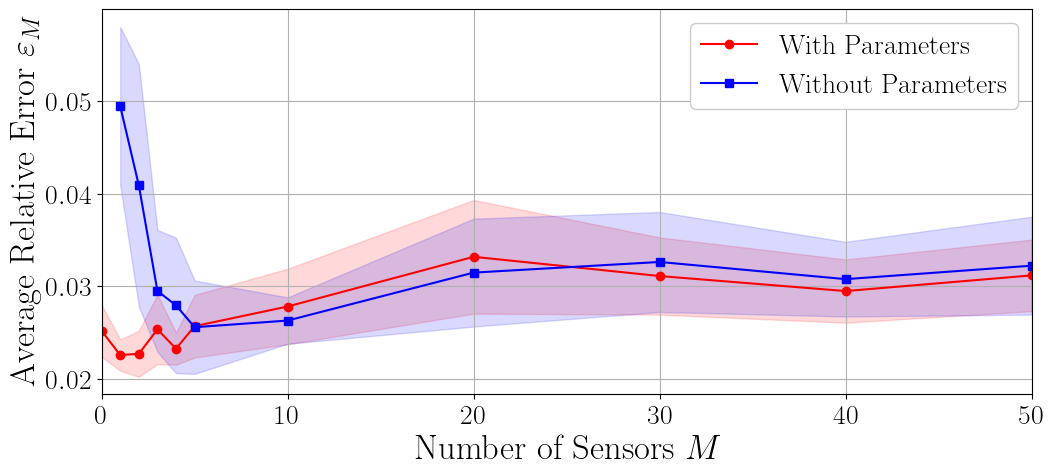

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 5))

mean_with = (np.linalg.norm(errors['NumSens_WithParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).mean(axis=0)
std_with  = (np.linalg.norm(errors['NumSens_WithParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).std(axis=0)

mean_without = (np.linalg.norm(errors['NumSens_WithoutParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).mean(axis=0)
std_without  = (np.linalg.norm(errors['NumSens_WithoutParam'], axis=-1) / np.linalg.norm(test_data, axis=0)).mean(axis=-1).std(axis=0)

ax.plot(num_senss, mean_with, color='r', marker='o', label='With Parameters')
ax.fill_between(num_senss, mean_with - std_with, mean_with + std_with, color='r', alpha=0.15)

ax.plot(num_senss[1:], mean_without, color='b', marker='s', label='Without Parameters')
ax.fill_between(num_senss[1:], mean_without - std_without, mean_without + std_without, color='b', alpha=0.15)

ax.set_xlabel('Number of Sensors $M$', fontsize=25)
ax.set_ylabel(r'Average Relative Error $ \varepsilon_M$', fontsize=25)
ax.legend(framealpha=1, ncols=1, fontsize=20, loc='upper right')
ax.grid()
ax.set_xlim(0, num_senss[-1])
ax.tick_params(axis='both', which='major', labelsize=20)
fig.savefig(path_res + f'ave_rel_err_sensitivity{_stats}.pdf', bbox_inches='tight', dpi=300)


Let us observe how the residual field, defined as $\mathbf{r}_M = |\mathbf{u} - \mathbf{u}_M|$, is spread over the core adopting a statistical approach.

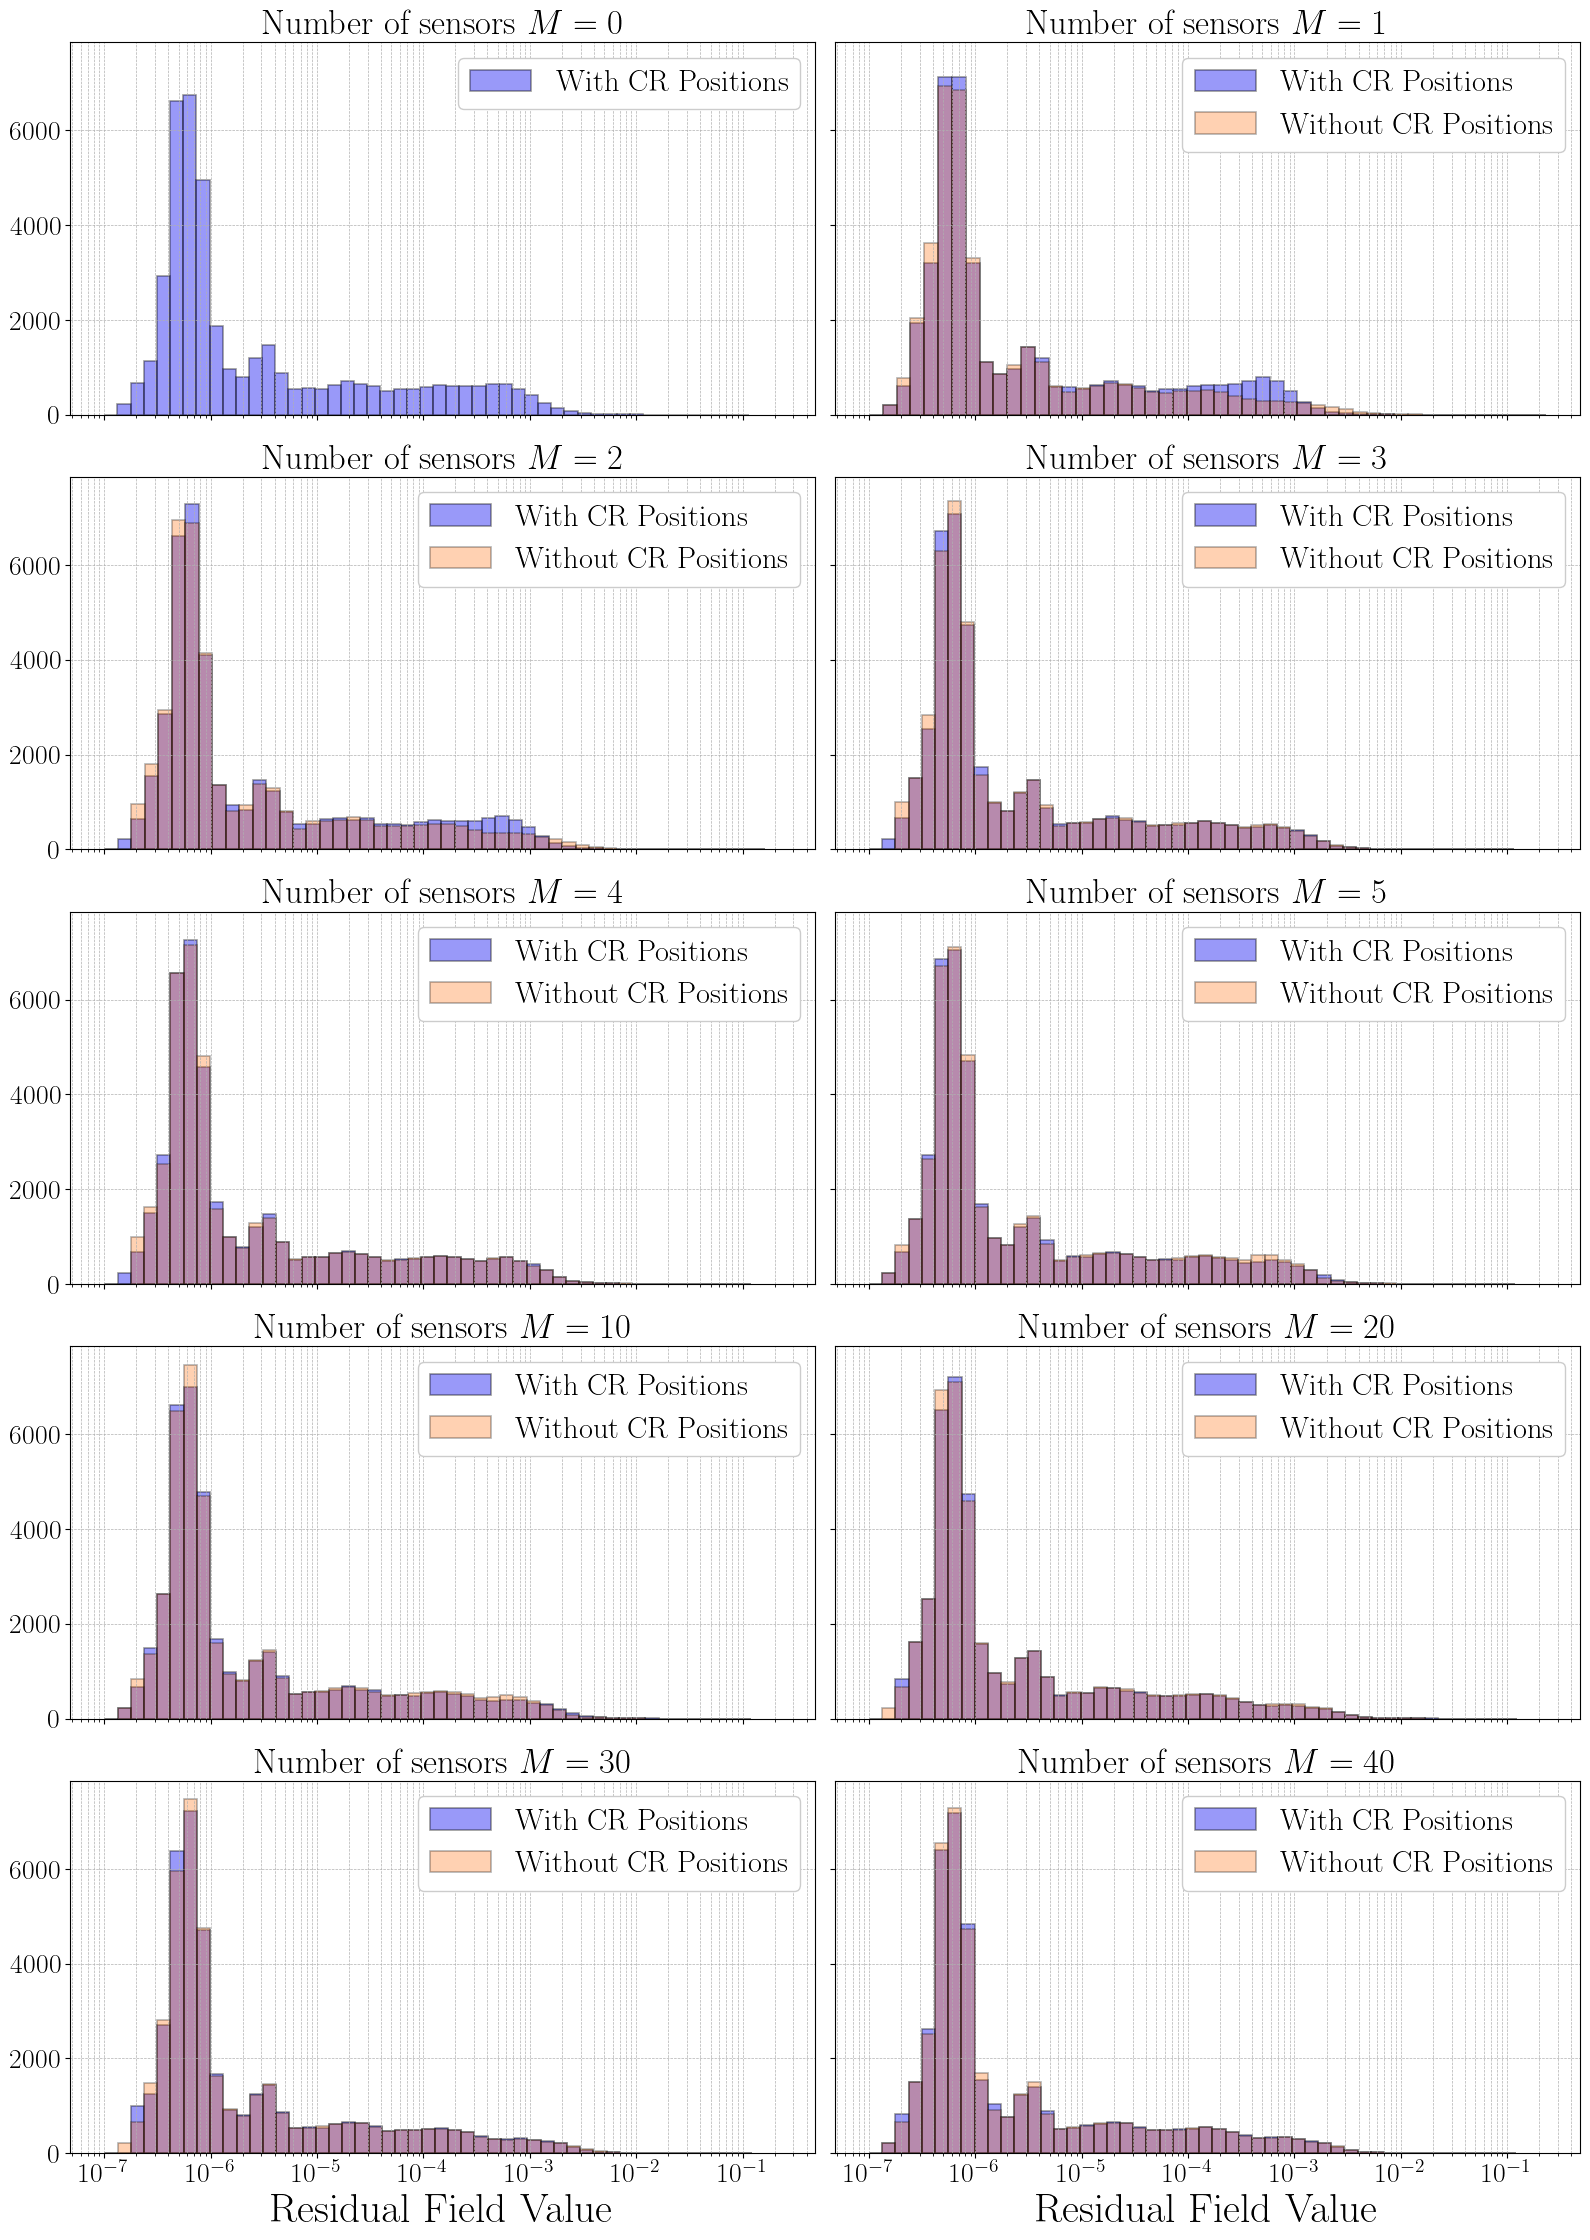

In [18]:
from matplotlib import cm
import seaborn as sns

residuals_with_per_condition = [errors['NumSens_WithParam'].mean(axis=2).mean(axis=0)[i, :] for i in range(len(num_senss))]
residuals_without_per_condition = [errors['NumSens_WithoutParam'].mean(axis=2).mean(axis=0)[i, :] for i in range(len(num_senss)-1)]

ncols = 2
nrows = 5
fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 4.5 * nrows), sharey=True, sharex=True)
axes = axes.flatten()

nbins = 50

for i in range(len(axes)):
    ax = axes[i]

    data = errors['NumSens_WithParam'].mean(axis=2).mean(axis=0)[i, :]
    bins = np.logspace(-7, np.log10(data.max()), nbins)
    if i > 0:
        data_without = errors['NumSens_WithoutParam'].mean(axis=2).mean(axis=0)[i-1, :]
        bins = np.logspace(-7, np.log10(max(data.max(), data_without.max())), nbins)
    ax.hist(data, bins=bins, color=cm.jet(0.1), alpha=0.4, edgecolor='black', linewidth=1.2, density=True, label='With CR Positions')

    if i > 0:
        ax.hist(data_without, bins=bins, color=cm.jet(0.8), alpha=0.3, edgecolor='black', linewidth=1.2, density=True, label='Without CR Positions')

    ax.set_xscale('log')
    ax.set_title('Number of sensors $M='+str(num_senss[i])+'$', fontsize=25)
    ax.grid(which='both', linestyle='--', linewidth=0.5)
    ax.tick_params(axis='both', which='major', labelsize=20)
    ax.legend(framealpha=1, ncols=1, fontsize=22, loc='upper right')
    
    if i >= (ncols * (nrows - 1)):
        ax.set_xlabel('Residual Field Value', fontsize=30)

for i in range(len(residuals_with_per_condition), len(axes)):
    axes[i].axis('off')  # Hide unused subplots

plt.tight_layout()

# _line, _labels = axes[1].get_legend_handles_labels()
# axes[-1].legend(_line, _labels, framealpha=1, ncols=1, fontsize=18, loc='upper left')

fig.savefig(path_res + f'residual_hist{_stats}.pdf', bbox_inches='tight', dpi=300)

Let us make a violin plot of the residual field for each number of sensors, with and without operational parameters.

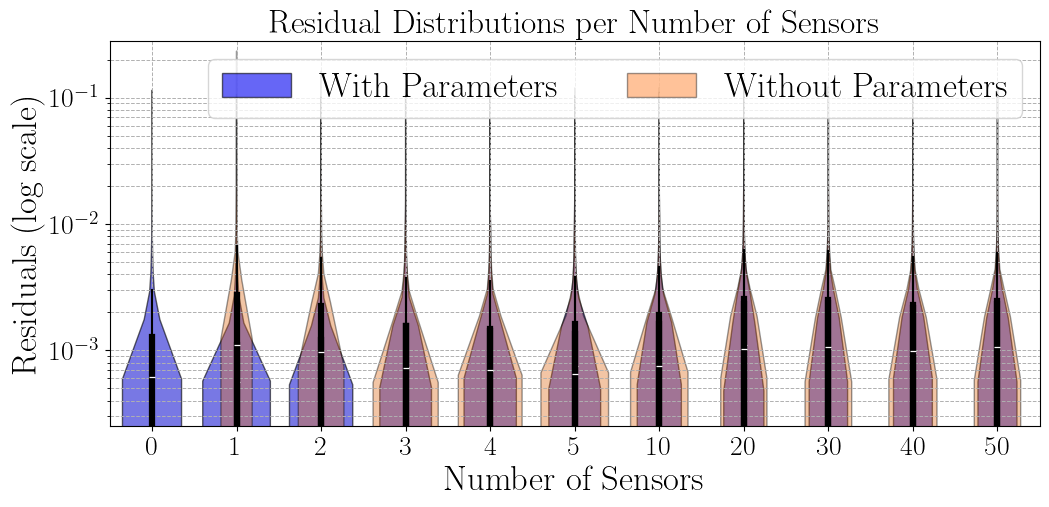

In [19]:
from matplotlib.patches import Patch


# Prepare data
residuals_with_per_condition = [errors['NumSens_WithParam'].mean(axis=2).mean(axis=0)[i, :] for i in range(len(num_senss))]
residuals_without_per_condition = [np.nan * np.ones_like(residuals_with_per_condition[0])] + [
    errors['NumSens_WithoutParam'].mean(axis=2).mean(axis=0)[i, :] for i in range(len(num_senss) - 1)
]

fig, ax = plt.subplots(figsize=(12, 5), sharey=True, sharex=True)

# Violin plots with edge colors for visibility
sns.violinplot(
    data=residuals_with_per_condition,
    color=cm.jet(0.1),
    alpha=0.6,
    linewidth=1,
    edgecolor='black',
    width=0.8,
    ax=ax
)

sns.violinplot(
    data=residuals_without_per_condition,
    color=cm.jet(0.8),
    alpha=0.4,
    linewidth=1,
    edgecolor='black',
    width=0.8,
    ax=ax
)

# Log scale on y-axis
ax.set_yscale('log')

# Set y-limits roughly to histogram range, adjust max_y as needed
max_y = max([arr.max() for arr in residuals_with_per_condition + residuals_without_per_condition if arr is not None and not np.all(np.isnan(arr))])
ax.set_ylim(2.5e-4, max_y*1.2)

# X-axis labels
ax.set_xticks(range(len(num_senss)))
ax.set_xticklabels([str(n) for n in num_senss], fontsize=22)
ax.set_xlabel('Number of Sensors', fontsize=25)

# Y-axis label
ax.set_ylabel('Residuals (log scale)', fontsize=25)

# Legend with matched colors
legend_elements = [
    Patch(facecolor=cm.jet(0.1), edgecolor='k', alpha=0.6, label='With Parameters'),
    Patch(facecolor=cm.jet(0.8), edgecolor='k', alpha=0.4, label='Without Parameters')
]
ax.legend(handles=legend_elements, fontsize=25, ncol=2, loc='upper right')

# Grid and title
ax.grid(True, which='both', linestyle='--', linewidth=0.7)
ax.set_title('Residual Distributions per Number of Sensors', fontsize=24)
ax.tick_params(axis='both', which='major', labelsize=20)

fig.savefig(path_res + f'violin_plot_sens{_stats}.pdf', bbox_inches='tight', dpi=300)